<a href="https://colab.research.google.com/github/yibesh/DeepLearning/blob/main/YOLO_Object_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Beginner Lab: Object Detection with YOLO

**Course practical:** Run a pretrained YOLO model to detect several objects in one image.

### Learning outcomes
By completing this lab, you will learn to:
1. Load a pretrained YOLO model.
2. Upload an image and detect multiple object categories.
3. View bounding boxes, class names, and confidence scores.
4. Count detected objects.
5. Compare results using different confidence thresholds.

**Model note:** This notebook uses the pretrained `yolo26s.pt` model (small). It is larger than the nano model and may classify objects more accurately, although no model is perfect. It recognizes the 80 categories in the COCO dataset.

## 1. Install and import libraries
Run this cell once in a new Google Colab session.

In [38]:
!pip -q install -U ultralytics

from ultralytics import YOLO
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

print("Setup complete!")

Setup complete!


## 2. Load the pretrained YOLO model

We use `yolo26s.pt` (small) instead of `yolo26n.pt` (nano). The small model is a useful choice when recognition quality is more important than maximum speed.

The model weights are downloaded automatically the first time this cell runs.

In [39]:
model = YOLO("yolov8x.pt")
print("YOLOv8x (Extra Large) model loaded!")

YOLOv8x (Extra Large) model loaded!


## 3. Upload an image

Upload one clear image containing several everyday objects, such as people, cars, bicycles, dogs, or cats.

**Tip:** Choose an image where objects are reasonably large, visible, and not heavily blocked.

Saving Capture21.PNG to Capture21 (3).PNG


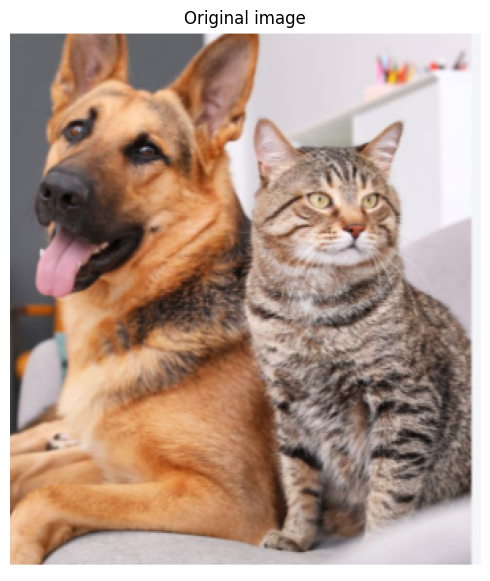

In [40]:
uploaded = files.upload()
image_path = next(iter(uploaded))

original_image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(10, 7))
plt.imshow(original_image)
plt.title("Original image")
plt.axis("off")
plt.show()

## 4. Detect objects

The `conf` setting is the minimum confidence threshold. We use `0.25` for this first run.

**Important:** Do not add `classes=[0]` to this prediction. That would restrict detection to people only. Leaving out the `classes` setting allows YOLO to detect all supported categories.

In [41]:
results = model.predict(
    source=image_path,
    conf=0.25,
    verbose=False
)

result = results[0]
print("Detection complete!")
print("Number of detected objects:", len(result.boxes))

Detection complete!
Number of detected objects: 2


## 5. Display the detected objects

YOLO draws a bounding box, predicted class name, and confidence score for each detection.

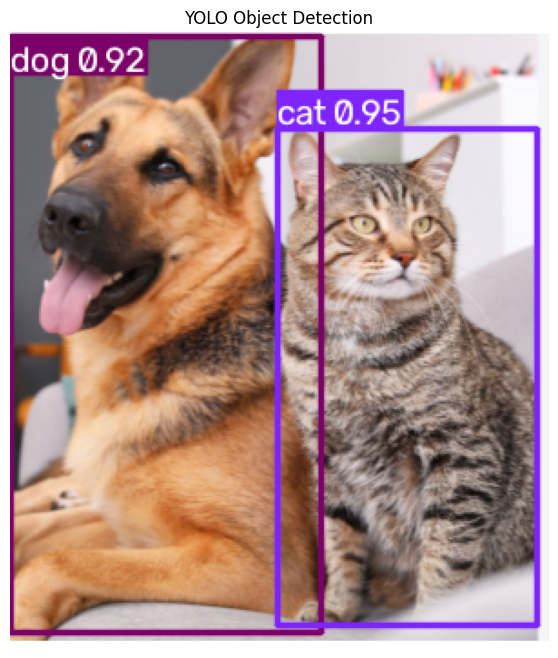

In [42]:
annotated_image = result.plot()

# Convert BGR (YOLO output) to RGB (Matplotlib format)
annotated_image_rgb = annotated_image[:, :, ::-1]

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image_rgb)
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()

## 6. Read the detection results

The table shows the predicted class, class ID, and confidence score for each detected object.

For the COCO model, **cat = class ID 15** and **dog = class ID 16**.

In [43]:
rows = []

for box in result.boxes:
    class_id = int(box.cls[0])
    class_name = result.names[class_id]
    confidence = float(box.conf[0])

    rows.append({
        "Object": class_name,
        "Class ID": class_id,
        "Confidence": round(confidence, 3)
    })

if rows:
    detections_df = pd.DataFrame(rows)
    display(detections_df)

    print("Object counts:")
    display(
        detections_df["Object"]
        .value_counts()
        .rename_axis("Object")
        .reset_index(name="Count")
    )
else:
    print("No objects detected. Try another clear image or a lower confidence threshold.")

,Object,Class ID,Confidence
0,cat,15,0.954
1,dog,16,0.917


Object counts:


,Object,Count
0,cat,1
1,dog,1


### Check the dog and cat predictions

If the model labels a dog as a cat, this is a **classification error**. The bounding box may locate the object correctly while the predicted category is wrong.

A confidence score is the model's score for its prediction; it is not a guarantee that the label is correct. A larger model may help, but it cannot guarantee a correct result for every image.

For the COCO model:
- Cat = 15
- Dog = 16

The next cell prints only predictions for these two categories, if present.

In [44]:
for box in result.boxes:
    class_id = int(box.cls[0])

    if class_id in [15, 16]:
        print(
            "Predicted:", result.names[class_id],
            "| Class ID:", class_id,
            "| Confidence:", round(float(box.conf[0]), 3)
        )

Predicted: cat | Class ID: 15 | Confidence: 0.954
Predicted: dog | Class ID: 16 | Confidence: 0.917


## 7. Experiment: change the confidence threshold

Compare three confidence thresholds on the same image.

- **0.10:** keeps more predictions, but may include false detections.
- **0.25:** a moderate starting value.
- **0.50:** keeps fewer, more confident predictions, but may miss real objects.

Changing the threshold filters predictions. It does not teach the model new object categories or guarantee correction of a wrong class label.

Threshold: 0.10 | Detected objects: 2


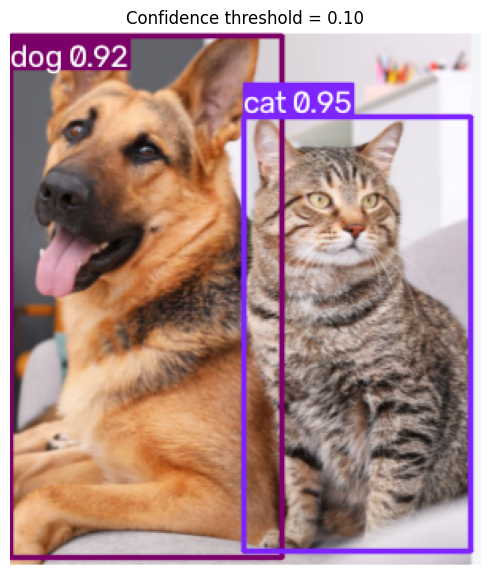

Threshold: 0.25 | Detected objects: 2


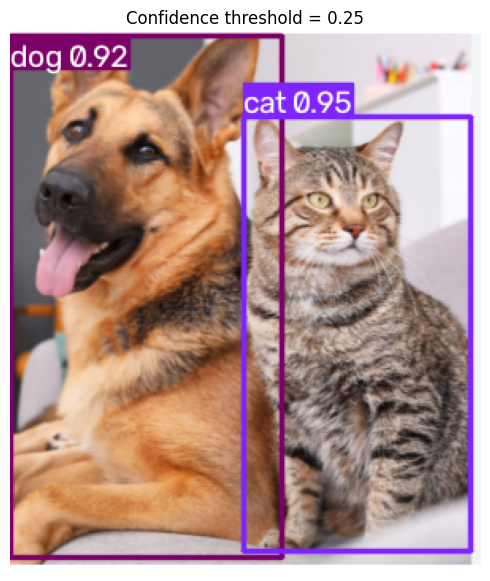

Threshold: 0.50 | Detected objects: 2


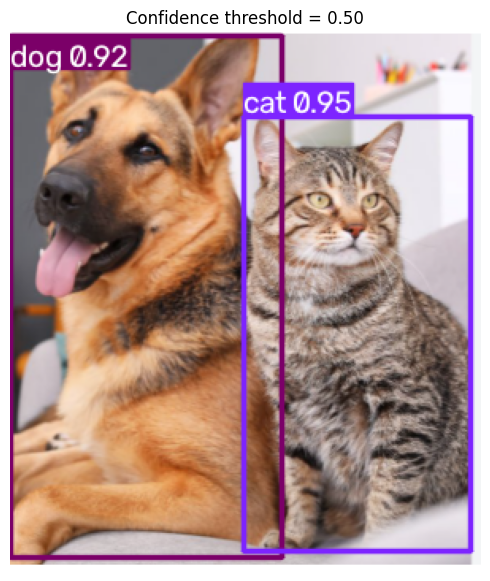

In [45]:
for threshold in [0.10, 0.25, 0.50]:
    threshold_result = model.predict(
        source=image_path,
        conf=threshold,
        verbose=False
    )[0]

    print(
        f"Threshold: {threshold:.2f} | "
        f"Detected objects: {len(threshold_result.boxes)}"
    )

    image_with_boxes = threshold_result.plot()[:, :, ::-1]

    plt.figure(figsize=(10, 7))
    plt.imshow(image_with_boxes)
    plt.title(f"Confidence threshold = {threshold:.2f}")
    plt.axis("off")
    plt.show()

## 8. Save the detection result

Download the image with YOLO's bounding boxes and labels.

In [46]:
output_path = "yolo_detection_result.jpg"
Image.fromarray(annotated_image_rgb).save(output_path)
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### YOLO Model Comparison

Ultralytics YOLOv8 offers models of various sizes to suit different needs:
- **YOLOv8n (Nano)**: Fastest and smallest. Optimized for mobile and CPU deployment, but has the lowest accuracy.
- **YOLOv8s (Small)**: A great balance of speed and moderate accuracy.
- **YOLOv8m (Medium)**: Better accuracy with slightly higher computational cost.
- **YOLOv8l (Large)**: Highly accurate, suitable for server-side deployment.
- **YOLOv8x (Extra Large)**: Most accurate, but slowest and largest in size.

Let's write a script to run multiple YOLOv8 sizes on your image and compare their execution times, detected objects, and respective confidence scores.

In [50]:
import time
import pandas as pd

# Define correct model identifiers for Ultralytics YOLOv8, v9, v10, 11, and 12
compare_models = {
    "YOLOv8n (Nano)": "yolov8n.pt",
    "YOLOv8x (Extra Large)": "yolov8x.pt",
    "YOLOv9c (Medium)": "yolov9c.pt",
    "YOLOv10n (Nano)": "yolov10n.pt",
    "YOLOv10x (Extra Large)": "yolov10x.pt",
    "YOLO11n (Nano)": "yolo11n.pt",
    "YOLO11x (Extra Large)": "yolo11x.pt",
    "YOLO12n (Nano)": "yolo12n.pt",
    "YOLO12x (Extra Large)": "yolo12x.pt"
}

comparison_results = []

for model_name, model_weights in compare_models.items():
    print(f"Evaluating {model_name}...")
    try:
        # Load model
        temp_model = YOLO(model_weights)

        # Measure prediction time
        start_time = time.time()
        temp_results = temp_model.predict(source=image_path, conf=0.25, verbose=False)[0]
        inference_time = (time.time() - start_time) * 1000  # Convert to milliseconds

        # Extract detected classes and average confidence
        detected_objects = []
        confidences = []
        for box in temp_results.boxes:
            class_id = int(box.cls[0])
            class_name = temp_results.names[class_id]
            confidence = float(box.conf[0])
            detected_objects.append(class_name)
            confidences.append(confidence)

        avg_conf = sum(confidences) / len(confidences) if confidences else 0.0

        comparison_results.append({
            "Model": model_name,
            "Objects Detected": ", ".join(detected_objects) if detected_objects else "None",
            "Count": len(detected_objects),
            "Avg Confidence": round(avg_conf, 3),
            "Inference Time (ms)": round(inference_time, 2)
        })
    except Exception as e:
        print(f"Could not evaluate {model_name}: {e}")

# Display the structured comparison table
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

Evaluating YOLOv8n (Nano)...
Evaluating YOLOv8x (Extra Large)...
Evaluating YOLOv9c (Medium)...
Evaluating YOLOv10n (Nano)...
Evaluating YOLOv10x (Extra Large)...
Evaluating YOLO11n (Nano)...
Evaluating YOLO11x (Extra Large)...
Evaluating YOLO12n (Nano)...
Evaluating YOLO12x (Extra Large)...


,Model,Objects Detected,Count,Avg Confidence,Inference Time (ms)
0,YOLOv8n (Nano),"cat, cat, dog",3,0.638,249.81
1,YOLOv8x (Extra Large),"cat, dog",2,0.935,3808.20
2,YOLOv9c (Medium),"cat, dog, bed",3,0.689,1772.00
3,YOLOv10n (Nano),"cat, dog, cat",3,0.585,248.25
4,YOLOv10x (Extra Large),"dog, cat",2,0.944,2597.32
5,YOLO11n (Nano),"cat, cat",2,0.839,239.24
6,YOLO11x (Extra Large),"dog, cat",2,0.947,4232.39
7,YOLO12n (Nano),"cat, cat, dog",3,0.676,321.37
8,YOLO12x (Extra Large),"cat, dog",2,0.934,3547.01


## 9. Object Detection on Video Files

In addition to static images, YOLO can process video files (`.mp4`, `.avi`, etc.) efficiently. The code below allows you to upload a video, run YOLO tracking or detection, and save the annotated video.

In [ ]:
# Upload your video file
print("Please upload a short video clip (e.g., .mp4 format):")
uploaded_video = files.upload()
video_path = next(iter(uploaded_video))
print(f"Uploaded video: {video_path}")

Please upload a short video clip (e.g., .mp4 format):


In [ ]:
# Run YOLO detection on the uploaded video
# We use stream=True for memory efficiency on larger video files
video_results = model.predict(
    source=video_path,
    conf=0.25,
    save=True,  # Automatically saves the annotated video
    verbose=True
)

print("Video processing complete!")
print(f"Annotated video saved in your runs/detect/predict folder.")

### 10. Mini exercise

Upload a different image containing at least three types of objects.

1. Predict which objects YOLO may detect.
2. Run the model and list the detected categories.
3. Compare the results at confidence thresholds 0.10, 0.25, and 0.50.
4. Identify one correct detection and, if present, one incorrect or missed detection.

**Remember:** YOLO detects only categories it has been trained to recognize. Results can be affected by image quality, lighting, object size, camera angle, and occlusion.

## 11. Quick review

1. What is the difference between image classification and object detection?
2. What information does a bounding box provide?
3. What does the confidence score represent?
4. What usually happens when the confidence threshold increases?
5. Why might YOLO classify a dog as a cat?
6. What is the difference between class ID 15 and class ID 16 in the COCO model?

